In [1]:
import torch

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [3]:
import torchvision

from torchvision import datasets
from torchvision import transforms

In [4]:
train_data = datasets.MNIST(root=".", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(root=".", train=False, download=True, transform=transforms.ToTensor())

In [5]:
train_data , test_data

(Dataset MNIST
     Number of datapoints: 60000
     Root location: .
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset MNIST
     Number of datapoints: 10000
     Root location: .
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [6]:
len(train_data) , len(test_data)

(60000, 10000)

In [7]:
img = train_data[0][0]
label = train_data[0][1]

print("image: {img}")
print(img.shape)

print("Label: {label}")

image: {img}
torch.Size([1, 28, 28])
Label: {label}


In [8]:
class_names = train_data.classes
class_names

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

torch.Size([1, 28, 28])
torch.Size([28, 28])
torch.Size([1, 28, 28])
torch.Size([28, 28])
torch.Size([1, 28, 28])
torch.Size([28, 28])
torch.Size([1, 28, 28])
torch.Size([28, 28])
torch.Size([1, 28, 28])
torch.Size([28, 28])


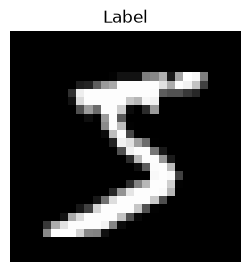

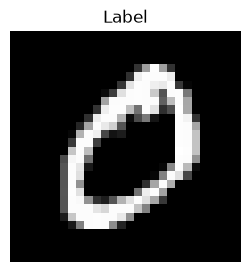

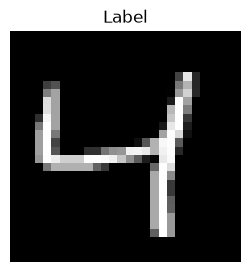

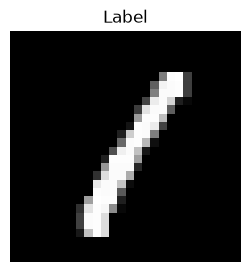

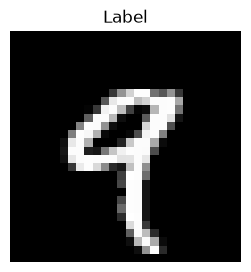

In [9]:
import matplotlib.pyplot as plt
for i in range(5):
    img = train_data[i][0]
    print(img.shape)

    img_squeezed = img.squeeze()
    print(img_squeezed.shape)

    label = train_data[0][1]

    plt.figure(figsize=(3,3))
    plt.imshow(img_squeezed , cmap = "gray")
    plt.title("Label")
    plt.axis(False)

In [33]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(dataset = train_data , batch_size= 32, shuffle = True)
test_dataloader = DataLoader(dataset = test_data , batch_size= 32, shuffle = True)

In [34]:
train_dataloader , test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x1775e023ec0>,
 <torch.utils.data.dataloader.DataLoader at 0x1775e075340>)

In [35]:
for sample in next(iter(train_dataloader)):
    print(sample.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


In [36]:
len(train_dataloader) , len(test_dataloader)

(1875, 313)

In [37]:
from torch import nn
class MNIST_model(torch.nn.Module):
    def __init__(self , input_shape: int , hidden_units: int , output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(nn.Conv2d(in_channels = input_shape , out_channels = hidden_units , kernel_size = 3, stride = 1 , padding = 1),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units , out_channels = hidden_units , kernel_size = 3, stride = 1 , padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2))

        self.conv_block_2 = nn.Sequential(nn.Conv2d(in_channels = hidden_units , out_channels = hidden_units , kernel_size = 3, stride = 1 , padding = 1),
        nn.ReLU(),
        nn.Conv2d(in_channels = hidden_units , out_channels = hidden_units , kernel_size = 3, stride = 1 , padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2))

        self.classifier = nn.Sequential(nn.Flatten() , nn.Linear(in_features = hidden_units*7*7 , out_features = output_shape))

    def forward(self , x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.classifier(x)

        return x

In [38]:
model = MNIST_model(input_shape = 3 , hidden_units = 10 , output_shape = 10).to(device)
model

MNIST_model(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [16]:
model.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 1.0596e-01, -4.7199e-02, -1.7653e-01],
                        [-1.2227e-01,  6.4467e-02, -6.8579e-02],
                        [-1.6231e-01, -9.3182e-02, -6.1993e-03]],
              
                       [[ 1.2942e-02, -7.1474e-02, -2.7786e-02],
                        [ 1.0694e-01, -1.8237e-01, -4.5689e-03],
                        [-1.3133e-01,  1.8703e-01,  6.3944e-02]],
              
                       [[-5.9854e-02,  1.3802e-01,  2.5323e-03],
                        [-1.3417e-01, -1.3119e-02,  2.9744e-03],
                        [ 9.9403e-03,  1.3738e-01, -1.6583e-01]]],
              
              
                      [[[-1.0417e-01,  8.6369e-04, -7.3172e-02],
                        [ 2.0746e-02,  1.1235e-01,  8.9842e-02],
                        [ 7.3450e-02, -7.8998e-02, -1.2662e-01]],
              
                       [[-6.3796e-02, -2.1888e-02,  5.5843e-02],
                        [-1.3844e-02

In [39]:
from tqdm.auto import tqdm
model_cpu = MNIST_model(input_shape=1,
                        hidden_units=10,
                        output_shape=10).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cpu.parameters() , lr = 0.1)

In [46]:
epochs = 5
for epoch in range(epochs):
    train_loss = 0
    for batch , (X , y) in enumerate(train_dataloader):
        model_cpu.train()

        X,y = X.to("cpu") , y.to("cpu")

        y_pred = model_cpu(X)

        loss = loss_fn(y_pred , y)
        train_loss += loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(train_dataloader)

    test_loss_total = 0
    model_cpu.eval()

    with torch.inference_mode():
        for batch, (X_test,y_test) in enumerate(test_dataloader):
            X_test , y_test = X_test.to("cpu") , y_test.to("cpu")

            y_test_pred = model_cpu(X_test)
            test_loss = loss_fn(y_test_pred , y_test)
            test_loss_total += test_loss

            test_loss /= len(test_dataloader)

    print(f"Epoch: {epoch} | Loss: {train_loss:.3f} | Test loss: {test_loss_total:.3f}")


Epoch: 0 | Loss: 0.281 | Test loss: 21.492
Epoch: 1 | Loss: 0.076 | Test loss: 22.671
Epoch: 2 | Loss: 0.059 | Test loss: 15.962
Epoch: 3 | Loss: 0.049 | Test loss: 15.291
Epoch: 4 | Loss: 0.042 | Test loss: 14.283


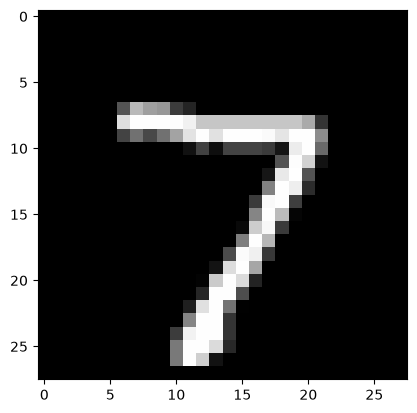

In [48]:
plt.imshow(test_data[0][0].squeeze() , cmap='gray')

In [49]:
model_pred_logits = model_cpu(test_data[0][0].unsqueeze(dim = 0).to(device))
model_pred_prob = torch.softmax(model_pred_logits , dim=1)
model_pred_labels = torch.argmax(model_pred_prob , dim = 1)
model_pred_labels

tensor([7])

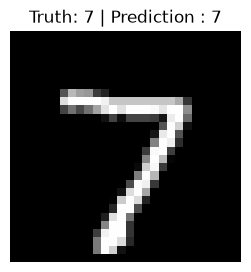

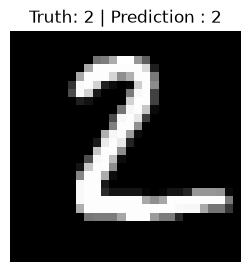

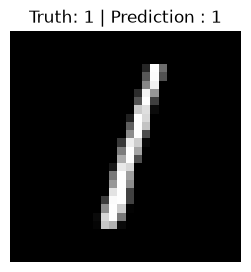

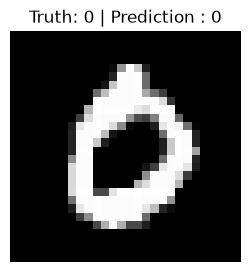

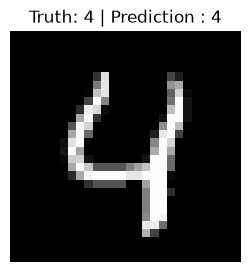

In [50]:
num_to_plot = 5
for i in range(num_to_plot):
    img = test_data[i][0]
    label = test_data[i][1]

    model_pred_labels = model_cpu(img.unsqueeze(dim = 0).to("cpu")).softmax(dim=1).argmax(dim=1)

    plt.figure(figsize=(3,3))
    plt.imshow(img.squeeze() , cmap = 'gray')
    plt.title(f"Truth: {label} | Prediction : {model_pred_labels.item()}")
    plt.axis(False)

In [51]:
from tqdm.auto import tqdm
model_cpu.eval()
y_preds = []
y_true = []
with torch.inference_mode():
    for batch,(X,y) in tqdm(enumerate(test_dataloader)):
        X,y = X.to("cpu") , y.to("cpu")
        y_pred_labels = model_cpu(X).argmax(dim=1)
        y_preds.append(y_pred_labels)
        y_true.append(y)

y_true = torch.cat(y_true).cpu()
y_preds = torch.cat(y_preds).cpu()

len(y_preds) , len(y_true)

313it [00:04, 71.41it/s] 


(10000, 10000)

In [52]:
test_data.targets[:10] , y_preds[:10]

(tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9]),
 tensor([6, 6, 3, 4, 5, 6, 6, 2, 2, 8]))

In [53]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [54]:
from torchmetrics import ConfusionMatrix
import numpy as np
confmat = ConfusionMatrix(num_classes = len(class_names) , task='multiclass')
confmat_tensor = confmat(preds = y_preds , target = y_true)


import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(conf_mat, class_names, figsize=(10, 7)):
    plt.figure(figsize=figsize)
    sns.heatmap(
        conf_mat,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title("Confusion Matrix")
    plt.show()

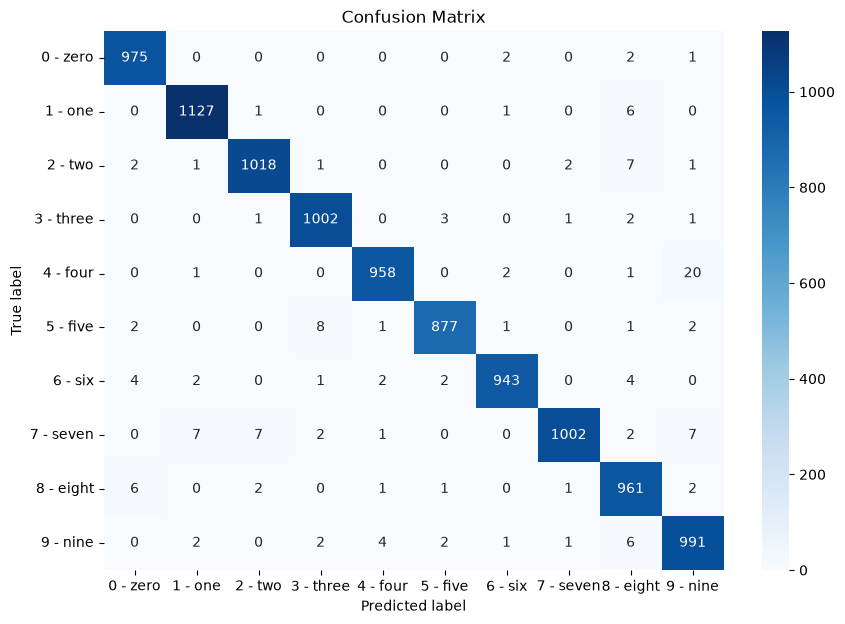

In [55]:
plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10, 7)
)

In [57]:
random_tensor = torch.rand([1,3,64,64])
random_tensor.shape

torch.Size([1, 3, 64, 64])

In [58]:
print(f"Random tensor original shape: {random_tensor.shape}")

conv_layer = nn.Conv2d(in_channels = 3 , out_channels = 64 , kernel_size = 3 , stride = 2, padding = 1)
random_tensor_through_conv_layer = conv_layer(random_tensor)
print(f"Random tensor through conv layer: {random_tensor_through_conv_layer.shape}")

Random tensor original shape: torch.Size([1, 3, 64, 64])
Random tensor through conv layer: torch.Size([1, 64, 32, 32])


In [59]:
from torchvision import datasets
from torchvision import transforms

fashion_mnist_train = datasets.FashionMNIST(root = '.' , download = True , train = True , transform = transforms.ToTensor())
fashion_mnist_test = datasets.FashionMNIST(root = '.' , download = True, train = False , transform = transforms.ToTensor())

len(fashion_mnist_train), len(fashion_mnist_test)

100%|██████████| 26.4M/26.4M [00:19<00:00, 1.38MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 190kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.1MB/s]


(60000, 10000)

In [60]:
fashion_mnist_class_names = fashion_mnist_train.classes
fashion_mnist_class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [61]:
from torch.utils.data import DataLoader

fashion_mnist_train_dataloader = DataLoader(fashion_mnist_train , batch_size = 32, shuffle = True)
fashion_mnist_test_dataloader = DataLoader(fashion_mnist_test , batch_size = 32, shuffle = False)

len(fashion_mnist_train_dataloader), len(fashion_mnist_test_dataloader)

(1875, 313)

In [62]:
model_2 = MNIST_model(input_shape=1, hidden_units = 10 , output_shape = 10).to("cpu")
model_2

MNIST_model(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [63]:
from torch import nn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_2.parameters() , lr = 0.01)

In [64]:
from torchmetrics import Accuracy
acc_fn = Accuracy(num_classes = len(fashion_mnist_class_names) , task = 'multiclass').to("cpu")

In [85]:
from tqdm.auto import tqdm

epochs = 5
for epoch in tqdm(range(epochs)):
    train_loss, test_loss_total = 0,0
    train_acc, test_acc = 0,0

    model_2.train()
    for batch, (X_train , y_train) in enumerate(fashion_mnist_train_dataloader):
        X_train , y_train = X_train.to(device) , y_train.to(device)
        y_pred = model_2(X_train)
        loss = loss_fn(y_pred , y_train)
        train_loss += loss.item()
        train_acc += acc_fn(y_pred , y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(fashion_mnist_train_dataloader)
    train_acc /= len(fashion_mnist_train_dataloader)

    model_2.eval()
    with torch.inference_mode():
            for batch, (X_test , y_test) in enumerate(fashion_mnist_test_dataloader):
                X_test , y_test = X_test.to(device) , y_test.to(device)
                y_pred_test = model_2(X_test)
                test_loss = loss_fn(y_pred_test , y_test)
                test_loss_total += test_loss.item()
                test_acc += acc_fn(y_pred_test , y_test)
        
    test_loss_total /= len(fashion_mnist_test_dataloader)
    test_acc = test_acc / len(fashion_mnist_test_dataloader)

    print(f"Epoch: {epoch} | Train loss: {train_loss:.3f} | Train acc: {train_acc:.2f} | Test loss: {test_loss_total:.3f} | Test acc: {test_acc:.2f}")

 20%|██        | 1/5 [02:46<11:06, 166.51s/it]

Epoch: 0 | Train loss: 0.303 | Train acc: 0.89 | Test loss: 0.337 | Test acc: 0.88


 40%|████      | 2/5 [12:10<20:01, 400.52s/it]

Epoch: 1 | Train loss: 0.296 | Train acc: 0.89 | Test loss: 0.319 | Test acc: 0.89


 60%|██████    | 3/5 [14:38<09:29, 284.87s/it]

Epoch: 2 | Train loss: 0.291 | Train acc: 0.90 | Test loss: 0.327 | Test acc: 0.88


 80%|████████  | 4/5 [24:30<06:46, 406.37s/it]

Epoch: 3 | Train loss: 0.286 | Train acc: 0.90 | Test loss: 0.314 | Test acc: 0.89


100%|██████████| 5/5 [51:48<00:00, 621.64s/it]

Epoch: 4 | Train loss: 0.283 | Train acc: 0.90 | Test loss: 0.314 | Test acc: 0.89


In [76]:
test_preds = []
model_2.eval()
with torch.inference_mode():
    for X_test , y_test in tqdm(fashion_mnist_train_dataloader):
        y_pred_labels = model_2(X_test.to(device)).softmax(dim=1).argmax(dim=1)

        test_preds.append(y_pred_labels.cpu())

test_preds = torch.cat(test_preds)
test_preds[:10] , len(test_preds)

100%|██████████| 1875/1875 [00:13<00:00, 134.52it/s]


(tensor([8, 6, 2, 4, 9, 8, 0, 4, 2, 2]), 60000)

In [ ]:
wrong_pred_indexes = np.where(
    test_preds[:len(fashion_mnist_test.targets)].numpy()
    != np.array(fashion_mnist_test.targets)
)[0]
len(wrong_pred_indexes)

C:\Users\HP\AppData\Local\Temp\ipykernel_46528\2384650040.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  wrong_pred_indexes = np.where(test_preds.numpy() != np.array(fashion_mnist_test.targets)[0])


1

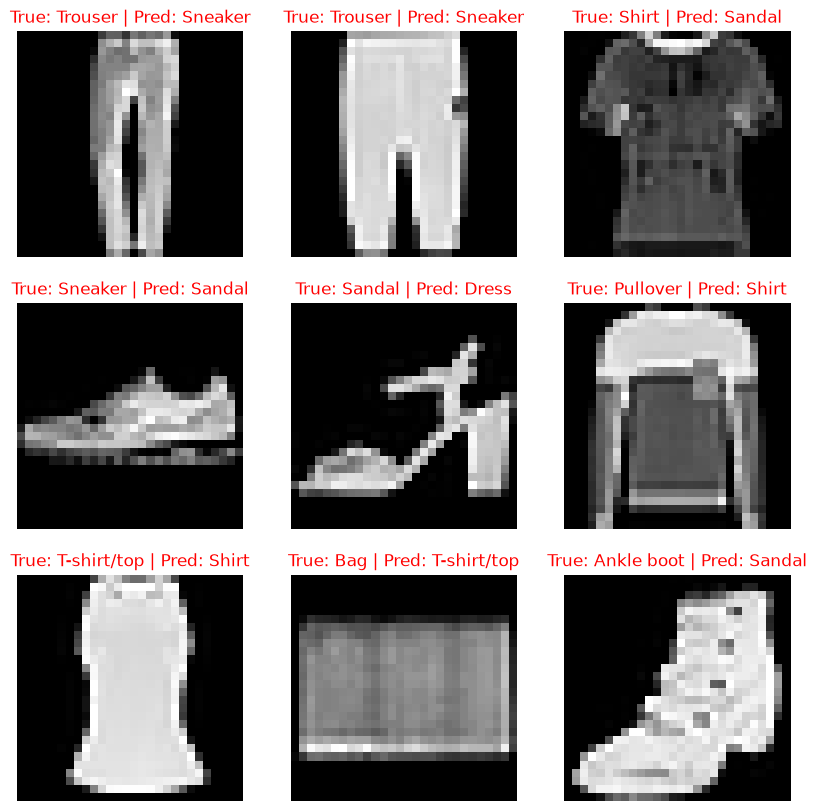

In [84]:
import random
random_selection = random.sample(wrong_pred_indexes.tolist(), k=min(9, len(wrong_pred_indexes)))

plt.figure(figsize = (10,10))
for i , idx in enumerate(random_selection):
    true_label = fashion_mnist_class_names[fashion_mnist_test[idx][1]]
    pred_label = fashion_mnist_class_names[test_preds[idx]]

    plt.subplot(3, 3, i+1)
    plt.imshow(fashion_mnist_test[idx][0].squeeze(), cmap="gray")
    plt.title(f"True: {true_label} | Pred: {pred_label}", c="r")
    plt.axis(False);